[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/diogoflim/iap/blob/main/03_Leonardo.ipynb)

# UNIVERSIDADE FEDERAL FLUMINENSE

**Introdução ao Aprendizado Profundo**

**Prof.: Diogo Ferreira de Lima Silva**

---
# AULA 03 — SUA PRIMEIRA REDE NEURAL
---

Na aula 2 treinamos uma **reta** com PyTorch. Hoje vamos trocar a reta por uma **rede neural** e ver que ela consegue aprender relações que uma reta não consegue.

**O que você vai aprender**

- montar uma rede neural com `nn.Sequential`;
- o que são **neurônios**, **camadas** e a **função de ativação** ReLU;
- escrever o laço de treinamento dentro de uma **função**, para reutilizá-lo;
- usar o modelo treinado para fazer previsões.

## 0. Importando as bibliotecas

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)      # fixa a semente: os resultados ficam iguais a cada execução

# cores usadas nos gráficos
LARANJA, AZUL, VERDE, VERMELHO, CINZA = "#E08D2B", "#1F7A8C", "#2E7D4F", "#B3151A", "#5B6472"

---
## 1. Dados
---

Vamos criar dados artificiais em que $y$ **sobe, desce e sobe de novo** conforme $x$ cresce. Pense, por exemplo, na demanda de um produto ao longo de um período, com altos e baixos.

A função `train_test_split` do scikit-learn separa os dados em **treino** (para o modelo aprender) e **teste** (para conferirmos se ele aprendeu de verdade).

In [2]:
from sklearn.model_selection import train_test_split

x = np.linspace(-3, 3, 120)                                  # 120 valores de x entre -3 e 3
y = np.sin(1.5 * x) + 0.3 * x + np.random.default_rng(42).normal(0, 0.15, 120)   

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.3, random_state=42)

print("exemplos de treino:", len(x_treino))
print("exemplos de teste :", len(x_teste))

exemplos de treino: 84
exemplos de teste : 36


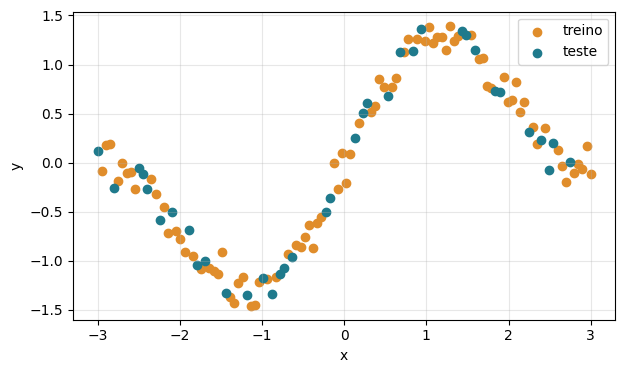

In [3]:
plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.scatter(x_teste, y_teste, color=AZUL, label="teste")
plt.xlabel("x"); plt.ylabel("y")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

---
## 2. Tensores
---

Como na aula passada: convertemos para tensores `float32` e usamos `.reshape(-1, 1)` para que cada **linha** seja um exemplo.

In [4]:
X_treino = torch.tensor(x_treino, dtype=torch.float32).reshape(-1, 1)
Y_treino = torch.tensor(y_treino, dtype=torch.float32).reshape(-1, 1)
X_teste  = torch.tensor(x_teste,  dtype=torch.float32).reshape(-1, 1)
Y_teste  = torch.tensor(y_teste,  dtype=torch.float32).reshape(-1, 1)

print("X_treino:", X_treino.shape)    

X_treino: torch.Size([84, 1])


---
## 3. Primeira tentativa: uma reta
---

Começamos com o modelo da aula passada, `nn.Linear(1, 1)`, para ter uma referência.

Uma novidade: usaremos o otimizador **Adam** em vez do SGD. Ele ajusta o tamanho do passo automaticamente e costuma funcionar bem sem muitos ajustes. Vamos usá-lo como padrão daqui em diante.

In [5]:
reta = nn.Linear(1, 1)

perda_fn = nn.MSELoss() # erro quadrático médio
otimizador = torch.optim.Adam(reta.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = reta(X_treino)               # 1. prever
    perda = perda_fn(previsao, Y_treino)    # 2. medir o erro
    otimizador.zero_grad()                  # 3. zerar os gradientes antigos
    perda.backward()                        # 4. calcular os gradientes
    otimizador.step()                       # 5. corrigir os parâmetros

print("perda final no treino:", perda.item())

perda final no treino: 0.47738465666770935


Para desenhar o modelo, pedimos previsões para muitos valores de $x$. O bloco `with torch.no_grad():` avisa ao PyTorch que **não** vamos treinar ali, apenas prever.

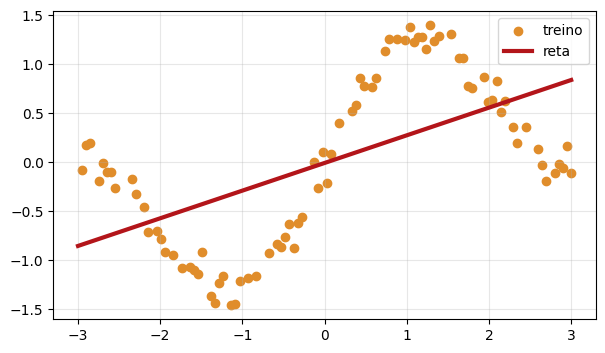

In [6]:
x_grade = torch.linspace(-3, 3, 200).reshape(-1, 1)     # 200 pontos para desenhar a curva (neste caso, uma reta)

with torch.no_grad():
    y_reta = reta(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=3, label="reta")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

A reta faz o melhor que pode, mas uma reta **nunca** vai subir, descer e subir de novo. Precisamos de um modelo mais flexível.

---
## 4. Uma rede neural
---

Criaremos uma rede neural rasa com os elementos a seguir?

```
entrada x  →  [ nn.Linear(1, 10) ]  →  [ nn.ReLU() ]  →  [ nn.Linear(10, 1) ]  →  saída y
               10 "neurônios"          ativação          junta os 10 em 1
```

- **`nn.Linear(1, 10)`**: transforma o $x$ em 10 números diferentes (cada um é uma reta com seus próprios parâmetros). Esses 10 números são as pré-ativações nos **neurônios** da **camada oculta**.
- **`nn.ReLU()`**: a **função de ativação**. Ela troca os números negativos por zero.
- **`nn.Linear(10, 1)`**: combina os 10 neurônios em uma única saída.

O `nn.Sequential` encaixa as peças na ordem em que aparecem.

### A função ReLU

A ReLU é muito simples: se o número é negativo, vira zero; se é positivo, fica como está.

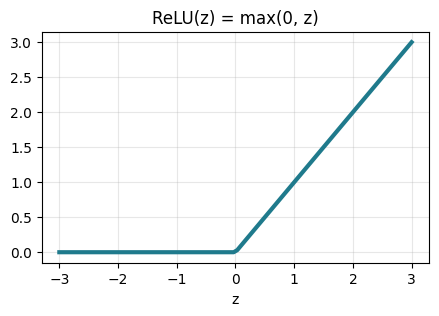

tensor([0., 0., 0., 1., 3.])


In [7]:
z = torch.linspace(-3, 3, 100)
relu = nn.ReLU()

plt.figure(figsize=(5, 3))
plt.plot(z, relu(z), color=AZUL, linewidth=3)
plt.title("ReLU(z) = max(0, z)"); plt.xlabel("z"); plt.grid(alpha=0.3)
plt.show()

print(relu(torch.tensor([-2.0, -0.5, 0.0, 1.0, 3.0])))

É justamente esse "dobrar" em zero que dá flexibilidade à rede: combinando várias retas dobradas, ela consegue formar curvas.

> **Por que não tirar a ReLU?** Sem ela, as duas camadas `nn.Linear` em sequência continuariam sendo, no fim das contas, uma reta. A ativação é o que torna a rede **não linear**.

### Montando a rede

In [8]:
rede = nn.Sequential(
    nn.Linear(1, 10),    # camada oculta: 10 neurônios
    nn.ReLU(),           # ativação
    nn.Linear(10, 1),    # camada de saída
)

print(rede)

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=1, bias=True)
)


Quantos parâmetros essa rede tem? O método `.parameters()` devolve todos eles, e `.numel()` conta quantos números há em cada um.

In [9]:
total = 0
for p in rede.parameters():
    print(p.shape)
    total = total + p.numel()

print("total de parâmetros:", total)

torch.Size([10, 1])
torch.Size([10])
torch.Size([1, 10])
torch.Size([1])
total de parâmetros: 31


A reta tinha 2 parâmetros. A rede tem 31. Mais parâmetros = mais flexibilidade.

---
## 5. Treinando a rede
---

Repare: o laço de treinamento é **exatamente o mesmo** da reta. Só trocamos `reta` por `rede`.

In [10]:
perda_fn = nn.MSELoss()
otimizador = torch.optim.Adam(rede.parameters(), lr=0.01)

for epoca in range(2000):
    previsao = rede(X_treino)
    perda = perda_fn(previsao, Y_treino)
    otimizador.zero_grad()
    perda.backward()
    otimizador.step()

    if epoca % 500 == 0:                     # mostra o progresso a cada 500 épocas
        print(f"época {epoca:4d} | perda = {perda.item():.4f}")

print("perda final no treino:", perda.item())

época    0 | perda = 0.4980


época  500 | perda = 0.0146
época 1000 | perda = 0.0142


época 1500 | perda = 0.0141


perda final no treino: 0.014034856110811234


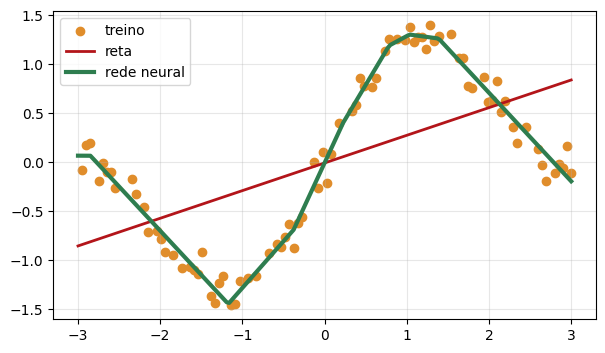

In [11]:
with torch.no_grad():
    y_rede = rede(x_grade)

plt.figure(figsize=(7, 4))
plt.scatter(x_treino, y_treino, color=LARANJA, label="treino")
plt.plot(x_grade, y_reta, color=VERMELHO, linewidth=2, label="reta")
plt.plot(x_grade, y_rede, color=VERDE, linewidth=3, label="rede neural")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

### Avaliando no teste

Para analisar se o modelo é capaz de generalizar para dados desconhecidos, utilizamos o conjunto de teste.

In [12]:
with torch.no_grad():
    erro_reta = perda_fn(reta(X_teste), Y_teste).item()
    erro_rede = perda_fn(rede(X_teste), Y_teste).item()

print(f"erro no teste (MSE) - reta: {erro_reta:.4f}")
print(f"erro no teste (MSE) - rede: {erro_rede:.4f}")

erro no teste (MSE) - reta: 0.4664
erro no teste (MSE) - rede: 0.0164


---
## 6. Guardando o treinamento em uma função
---

Vamos treinar várias redes daqui para frente. Para não copiar o laço toda vez, podemos colocar ele dentro de uma **função** no python. A função recebe o modelo, os dados e o número de épocas, treina, e devolve a lista com a perda de cada época.

In [13]:
def treinar(modelo, X, Y, epocas=2000, lr=0.01):
    perda_fn = nn.MSELoss()
    otimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historico = []

    for epoca in range(epocas):
        previsao = modelo(X)
        perda = perda_fn(previsao, Y)
        otimizador.zero_grad()
        perda.backward()
        otimizador.step()
        historico.append(perda.item())     # guarda a perda desta época

    return historico

Com a função, treinar uma rede nova fica em duas linhas:

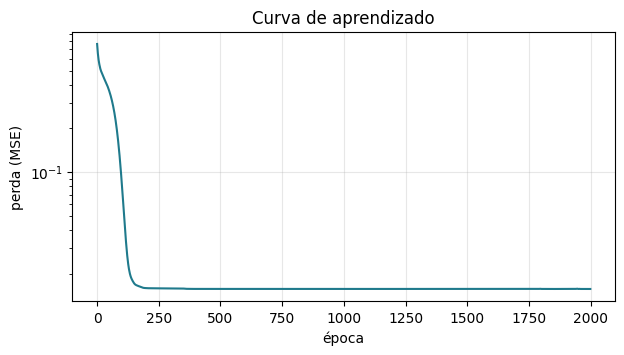

In [14]:
rede2 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
historico = treinar(rede2, X_treino, Y_treino)

plt.figure(figsize=(7, 3.5))
plt.plot(historico, color=AZUL)
plt.xlabel("época"); plt.ylabel("perda (MSE)"); plt.title("Curva de aprendizado")
plt.yscale("log"); plt.grid(alpha=0.3)
plt.show()

A **curva de aprendizado** mostra a perda caindo ao longo das épocas. É a primeira coisa a olhar quando treinamos um modelo: se ela não cai, algo está errado.

---
## 7. Quantos neurônios usar?
---

O número de neurônios da camada oculta é uma escolha nossa. Vamos comparar 1, 3, 10 e 100 neurônios.

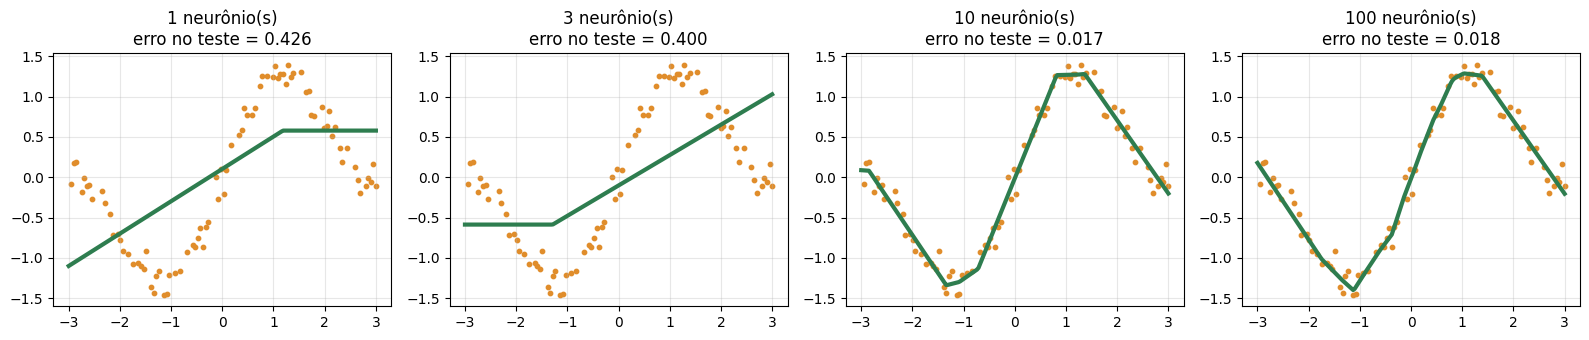

In [15]:
fig, eixos = plt.subplots(1, 4, figsize=(16, 3.5))

for eixo, n in zip(eixos, [1, 3, 10, 100]):
    torch.manual_seed(42)
    modelo = nn.Sequential(nn.Linear(1, n), nn.ReLU(), nn.Linear(n, 1))
    treinar(modelo, X_treino, Y_treino)

    with torch.no_grad():
        erro_teste = perda_fn(modelo(X_teste), Y_teste).item()
        eixo.plot(x_grade, modelo(x_grade), color=VERDE, linewidth=3)

    eixo.scatter(x_treino, y_treino, color=LARANJA, s=10)
    eixo.set_title(f"{n} neurônio(s)\nerro no teste = {erro_teste:.3f}")
    eixo.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Com **1 ou 3 neurônios**, a rede não acompanha a curva: há poucas "dobras" disponíveis. Com tão poucos neurônios, basta um deles ficar inativo (sempre zerado pela ReLU) para a rede perder a flexibilidade.
- A partir de **10 neurônios**, o ajuste fica bom.
- Ir para **100 neurônios** não melhora o teste: mais parâmetros do que o problema precisa não ajudam.

Escolher o tamanho da rede é uma decisão prática que voltará várias vezes no curso.

---
## 8. Usando o modelo para prever
---

Depois de treinado, o modelo funciona como uma função comum: damos um $x$, ele devolve um $y$.

In [16]:
novos_x = torch.tensor([[-2.0], [0.0], [1.0], [2.5]])

with torch.no_grad():
    previsoes = rede(novos_x)

for xv, yv in zip(novos_x, previsoes):
    print(f"x = {xv.item():5.1f}  ->  y previsto = {yv.item():6.3f}")

x =  -2.0  ->  y previsto = -0.698
x =   0.0  ->  y previsto = -0.005
x =   1.0  ->  y previsto =  1.286
x =   2.5  ->  y previsto =  0.257


---
## Exercícios
---

**1.** Troque `nn.ReLU()` por `nn.Tanh()` na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?

**2.** Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?

**3.** Crie uma rede com **duas** camadas ocultas de 10 neurônios. Dica: acrescente mais um `nn.Linear(10, 10)` e mais um `nn.ReLU()` no `nn.Sequential`.

**4.** Use a rede treinada para prever $y$ em $x = 10$, um valor bem fora dos dados de treino. O resultado faz sentido?

---
# RESOLUÇÃO DOS EXERCÍCIOS
---

**Aluno:** Leonardo

Nas células abaixo resolvo os quatro exercícios. Para comparar as variações de forma justa, uso sempre a mesma semente (`torch.manual_seed(42)`) antes de criar cada rede. Assim, a única diferença entre os modelos é a mudança pedida no exercício.

Como referência, crio uma rede ReLU idêntica à da Seção 4, treinada com a função `treinar` da Seção 6, e uma função auxiliar para medir o erro no teste.

In [17]:
def erro_teste(modelo):
    with torch.no_grad():
        return nn.MSELoss()(modelo(X_teste), Y_teste).item()

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

torch.manual_seed(42)
rede_relu = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
hist_relu = treinar(rede_relu, X_treino, Y_treino, epocas=2000)

print(f"ReLU (referência) | perda final no treino = {hist_relu[-1]:.4f} | erro no teste = {erro_teste(rede_relu):.4f}")

ReLU (referência) | perda final no treino = 0.0147 | erro no teste = 0.0171


---
### Exercício 1 — Trocando ReLU por Tanh

> Troque `nn.ReLU()` por `nn.Tanh()` na rede da Seção 4 e treine de novo. A curva ficou diferente? Como?

A tangente hiperbólica é uma curva suave em forma de "S" que vai de $-1$ a $1$. Diferente da ReLU, ela não tem uma "quina" em zero e também não zera os valores negativos.

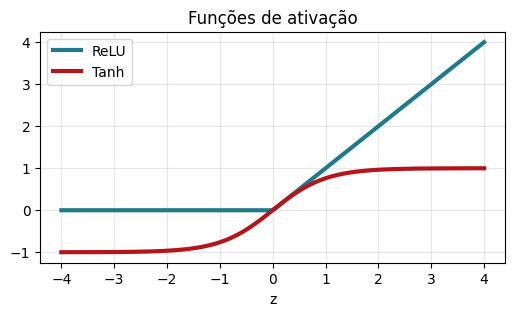

In [18]:
z = torch.linspace(-4, 4, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, nn.ReLU()(z), color=AZUL, linewidth=3, label="ReLU")
plt.plot(z, nn.Tanh()(z), color=VERMELHO, linewidth=3, label="Tanh")
plt.title("Funções de ativação"); plt.xlabel("z"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [19]:
torch.manual_seed(42)
rede_tanh = nn.Sequential(
    nn.Linear(1, 10),
    nn.Tanh(),           # única mudança em relação à rede da Seção 4
    nn.Linear(10, 1),
)
hist_tanh = treinar(rede_tanh, X_treino, Y_treino, epocas=2000)

print(f"ReLU | perda no treino = {hist_relu[-1]:.4f} | erro no teste = {erro_teste(rede_relu):.4f}")
print(f"Tanh | perda no treino = {hist_tanh[-1]:.4f} | erro no teste = {erro_teste(rede_tanh):.4f}")

ReLU | perda no treino = 0.0147 | erro no teste = 0.0171
Tanh | perda no treino = 0.0135 | erro no teste = 0.0132


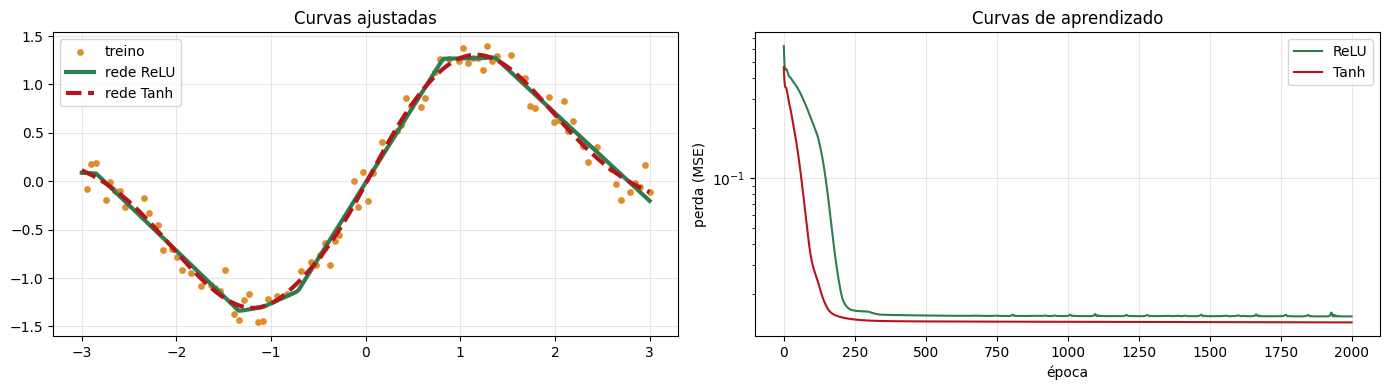

In [20]:
with torch.no_grad():
    y_relu = rede_relu(x_grade)
    y_tanh = rede_tanh(x_grade)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))

eixos[0].scatter(x_treino, y_treino, color=LARANJA, s=15, label="treino")
eixos[0].plot(x_grade, y_relu, color=VERDE, linewidth=3, label="rede ReLU")
eixos[0].plot(x_grade, y_tanh, color=VERMELHO, linewidth=3, linestyle="--", label="rede Tanh")
eixos[0].set_title("Curvas ajustadas"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(hist_relu, color=VERDE, label="ReLU")
eixos[1].plot(hist_tanh, color=VERMELHO, label="Tanh")
eixos[1].set_yscale("log"); eixos[1].set_xlabel("época"); eixos[1].set_ylabel("perda (MSE)")
eixos[1].set_title("Curvas de aprendizado"); eixos[1].legend(); eixos[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

Para enxergar melhor a diferença de **forma**, vale ampliar um trecho da curva. A derivada numérica também ajuda: a rede ReLU é formada por segmentos de reta, então sua inclinação muda "aos saltos". A rede Tanh tem inclinação que varia continuamente.

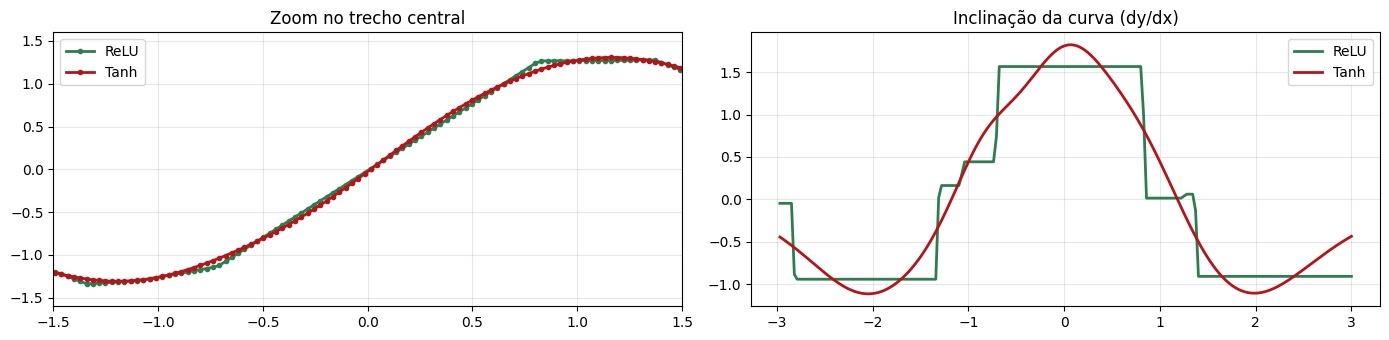

In [21]:
inclinacao_relu = torch.diff(y_relu.squeeze()) / torch.diff(x_grade.squeeze())
inclinacao_tanh = torch.diff(y_tanh.squeeze()) / torch.diff(x_grade.squeeze())

fig, eixos = plt.subplots(1, 2, figsize=(14, 3.5))
eixos[0].plot(x_grade, y_relu, color=VERDE, linewidth=2, marker=".", label="ReLU")
eixos[0].plot(x_grade, y_tanh, color=VERMELHO, linewidth=2, marker=".", label="Tanh")
eixos[0].set_xlim(-1.5, 1.5); eixos[0].set_ylim(-1.6, 1.6)
eixos[0].set_title("Zoom no trecho central"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(x_grade[1:], inclinacao_relu, color=VERDE, linewidth=2, label="ReLU")
eixos[1].plot(x_grade[1:], inclinacao_tanh, color=VERMELHO, linewidth=2, label="Tanh")
eixos[1].set_title("Inclinação da curva (dy/dx)"); eixos[1].legend(); eixos[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretação — Exercício 1**

**Sim, a curva ficou diferente, principalmente na forma.** No geral, as duas redes seguem o mesmo caminho: sobem, descem e sobem de novo. Os detalhes, porém, mudam bastante.

- **ReLU gera uma curva "quebrada".** A rede ReLU é formada por pedaços de reta ligados por quinas. Isso aparece no topo achatado perto de $x \approx 1$ e nos "cotovelos" perto de $x \approx -0.7$ e $x \approx 0.8$. O gráfico da inclinação mostra uma **escada**: a inclinação fica constante em cada pedaço e muda de uma vez em cada dobra.
- **Tanh gera uma curva suave.** Os picos e vales ficam arredondados, e a inclinação varia de forma contínua, parecida com uma onda. Isso faz sentido: cada neurônio contribui com um "S" suave, e a soma de curvas suaves é suave.
- **A Tanh se ajustou um pouco melhor aqui.** Ela chegou a uma perda menor no treino e a um erro menor no teste. A curva de aprendizado também caiu mais rápido. Minha interpretação é que a função verdadeira é um seno, que já é suave. Uma ativação suave "combina" melhor com ela do que pedaços de reta.
- **Cuidado com a conclusão.** A diferença de erro é pequena e vem de uma única semente. Não dá para dizer que a Tanh é sempre melhor. Em redes profundas, a ReLU costuma ser preferida porque a Tanh **satura**: para entradas muito grandes ou muito pequenas ela fica achatada em $\pm 1$, e o gradiente quase some. Esse achatamento volta a aparecer no Exercício 4.

---
### Exercício 2 — Treinando com apenas 200 épocas

> Treine a rede com apenas 200 épocas em vez de 2000. O que acontece com o ajuste?

Crio a rede com a mesma semente da referência. Assim, ela parte exatamente dos mesmos pesos iniciais e só difere no tempo de treino.

In [22]:
torch.manual_seed(42)
rede_200 = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
hist_200 = treinar(rede_200, X_treino, Y_treino, epocas=200)

print(f" 200 épocas | perda no treino = {hist_200[-1]:.4f} | erro no teste = {erro_teste(rede_200):.4f}")
print(f"2000 épocas | perda no treino = {hist_relu[-1]:.4f} | erro no teste = {erro_teste(rede_relu):.4f}")

 200 épocas | perda no treino = 0.0214 | erro no teste = 0.0225
2000 épocas | perda no treino = 0.0147 | erro no teste = 0.0171


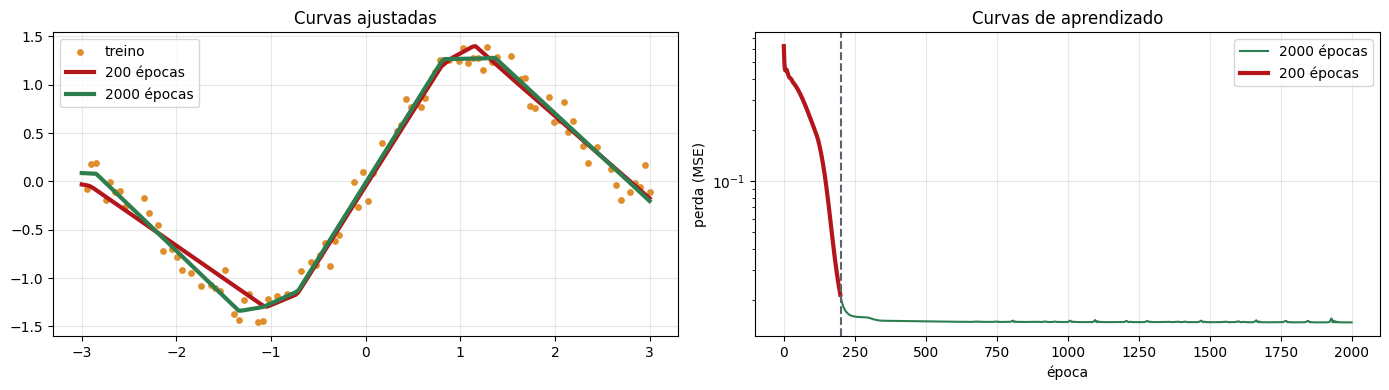

In [23]:
with torch.no_grad():
    y_200 = rede_200(x_grade)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
eixos[0].scatter(x_treino, y_treino, color=LARANJA, s=15, label="treino")
eixos[0].plot(x_grade, y_200, color=VERMELHO, linewidth=3, label="200 épocas")
eixos[0].plot(x_grade, y_relu, color=VERDE, linewidth=3, label="2000 épocas")
eixos[0].set_title("Curvas ajustadas"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(hist_relu, color=VERDE, label="2000 épocas")
eixos[1].plot(hist_200, color=VERMELHO, linewidth=3, label="200 épocas")
eixos[1].axvline(200, color=CINZA, linestyle="--")
eixos[1].set_yscale("log"); eixos[1].set_xlabel("época"); eixos[1].set_ylabel("perda (MSE)")
eixos[1].set_title("Curvas de aprendizado"); eixos[1].legend(); eixos[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Para entender **como** o ajuste evolui, treino a mesma rede (mesma semente) por diferentes números de épocas e desenho a curva em cada etapa.

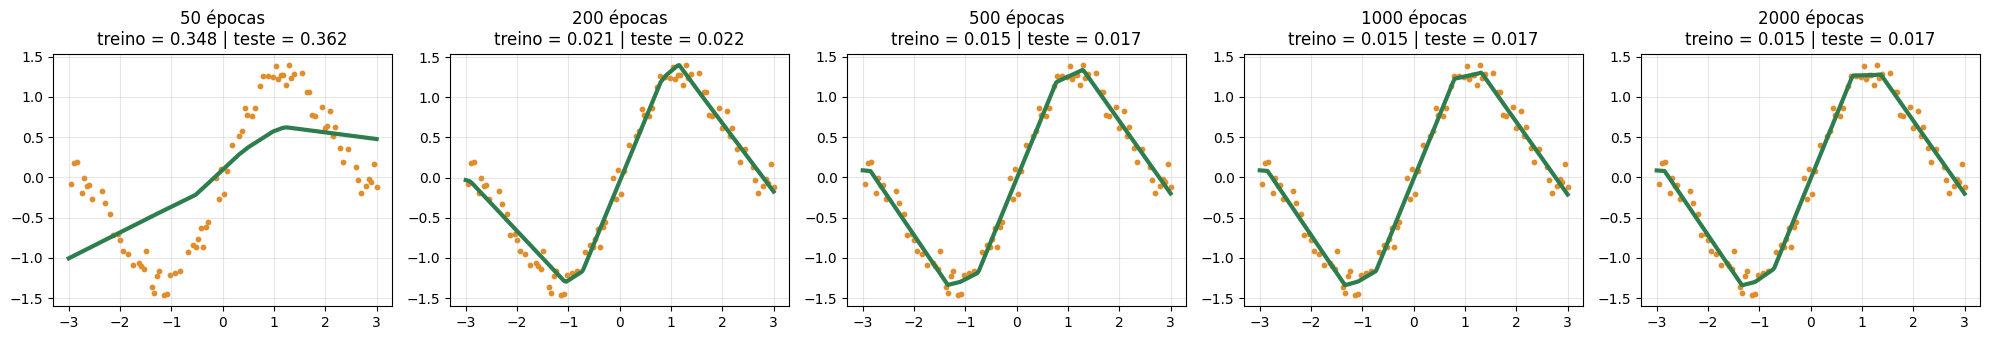

In [24]:
lista_epocas = [50, 200, 500, 1000, 2000]
fig, eixos = plt.subplots(1, len(lista_epocas), figsize=(20, 3.5))

for eixo, ep in zip(eixos, lista_epocas):
    torch.manual_seed(42)
    modelo = nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))
    hist = treinar(modelo, X_treino, Y_treino, epocas=ep)
    with torch.no_grad():
        eixo.plot(x_grade, modelo(x_grade), color=VERDE, linewidth=3)
    eixo.scatter(x_treino, y_treino, color=LARANJA, s=10)
    eixo.set_title(f"{ep} épocas\ntreino = {hist[-1]:.3f} | teste = {erro_teste(modelo):.3f}")
    eixo.grid(alpha=0.3)

plt.tight_layout(); plt.show()

**Interpretação — Exercício 2**

**Com 200 épocas, a rede fica com um ajuste incompleto: um caso leve de subajuste (*underfitting*).** Ela já capta o formato geral de "sobe, desce, sobe", mas erra nos detalhes.

- **O treino foi interrompido no meio da descida.** Na curva de aprendizado, a perda ainda está caindo rápido na época 200 (linha tracejada). A rede simplesmente não teve tempo de terminar de ajustar os parâmetros.
- **Os detalhes da curva ficam errados.** O pico perto de $x \approx 1.1$ fica pontudo e passa um pouco acima dos dados, em vez do topo achatado que acompanha os pontos. O vale da esquerda fica deslocado para perto de $x \approx -1.0$, quando os dados indicam algo perto de $x \approx -1.3$. O trecho da esquerda vira praticamente uma única reta.
- **Os erros são maiores.** O erro no treino e no teste ficam visivelmente acima dos valores obtidos com 2000 épocas.
- **A sequência de épocas mostra a evolução.** Com 50 épocas, a rede ainda é quase uma reta torta e não acompanha os dados. Com 200, o formato aparece. A partir de cerca de 500 épocas, os erros praticamente param de cair: 500, 1000 e 2000 épocas dão o mesmo resultado.

**Conclusão:** 200 épocas são poucas para este problema, mas 2000 são mais que suficientes. Com este otimizador e esta taxa de aprendizado, algo em torno de 500 épocas já bastaria. É por isso que a curva de aprendizado é tão útil: ela mostra se ainda vale a pena continuar treinando. Esse número depende do otimizador e do `lr`; com o SGD da aula passada, provavelmente seriam necessárias mais épocas.

---
### Exercício 3 — Duas camadas ocultas

> Crie uma rede com **duas** camadas ocultas de 10 neurônios.

A nova rede tem o formato:

```
x → [Linear(1, 10)] → [ReLU] → [Linear(10, 10)] → [ReLU] → [Linear(10, 1)] → y
```

In [25]:
torch.manual_seed(42)
rede_2camadas = nn.Sequential(
    nn.Linear(1, 10),     # 1ª camada oculta
    nn.ReLU(),
    nn.Linear(10, 10),    # 2ª camada oculta
    nn.ReLU(),
    nn.Linear(10, 1),     # camada de saída
)
print(rede_2camadas)

for nome, p in rede_2camadas.named_parameters():
    print(f"{nome:10s} {str(tuple(p.shape)):10s} -> {p.numel():3d} parâmetros")

print("\ntotal (2 camadas ocultas):", contar_parametros(rede_2camadas))
print("total (1 camada oculta)  :", contar_parametros(rede_relu))

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): ReLU()
  (2): Linear(in_features=10, out_features=10, bias=True)
  (3): ReLU()
  (4): Linear(in_features=10, out_features=1, bias=True)
)
0.weight   (10, 1)    ->  10 parâmetros
0.bias     (10,)      ->  10 parâmetros
2.weight   (10, 10)   -> 100 parâmetros
2.bias     (10,)      ->  10 parâmetros
4.weight   (1, 10)    ->  10 parâmetros
4.bias     (1,)       ->   1 parâmetros

total (2 camadas ocultas): 141
total (1 camada oculta)  : 31


A camada `Linear(10, 10)` sozinha acrescenta $10 \times 10 = 100$ pesos e mais $10$ vieses. Por isso a rede passa de 31 para 141 parâmetros.

In [26]:
hist_2camadas = treinar(rede_2camadas, X_treino, Y_treino, epocas=2000)

print(f"1 camada oculta  | perda no treino = {hist_relu[-1]:.4f} | erro no teste = {erro_teste(rede_relu):.4f}")
print(f"2 camadas ocultas| perda no treino = {hist_2camadas[-1]:.4f} | erro no teste = {erro_teste(rede_2camadas):.4f}")

1 camada oculta  | perda no treino = 0.0147 | erro no teste = 0.0171
2 camadas ocultas| perda no treino = 0.0124 | erro no teste = 0.0139


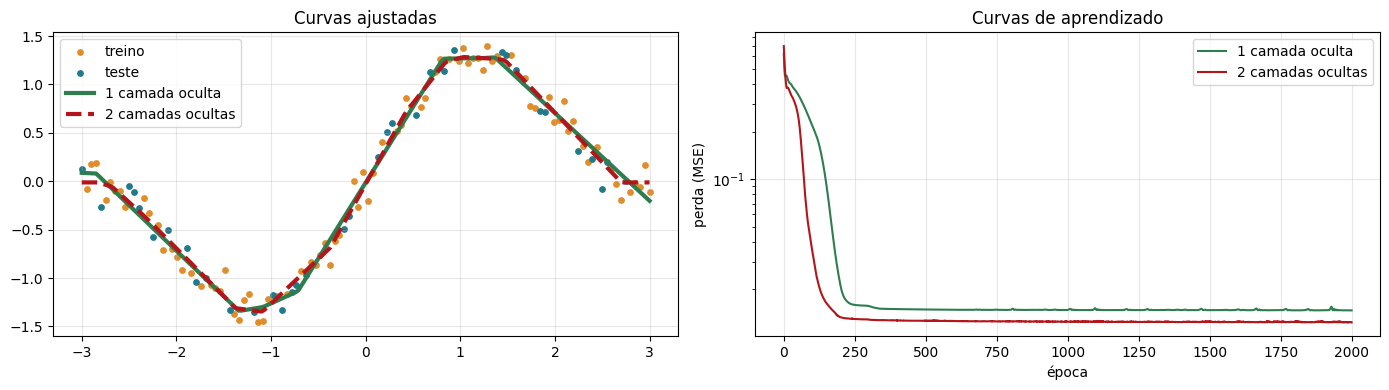

In [27]:
with torch.no_grad():
    y_2camadas = rede_2camadas(x_grade)

fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
eixos[0].scatter(x_treino, y_treino, color=LARANJA, s=15, label="treino")
eixos[0].scatter(x_teste, y_teste, color=AZUL, s=15, label="teste")
eixos[0].plot(x_grade, y_relu, color=VERDE, linewidth=3, label="1 camada oculta")
eixos[0].plot(x_grade, y_2camadas, color=VERMELHO, linewidth=3, linestyle="--", label="2 camadas ocultas")
eixos[0].set_title("Curvas ajustadas"); eixos[0].legend(); eixos[0].grid(alpha=0.3)

eixos[1].plot(hist_relu, color=VERDE, label="1 camada oculta")
eixos[1].plot(hist_2camadas, color=VERMELHO, label="2 camadas ocultas")
eixos[1].set_yscale("log"); eixos[1].set_xlabel("época"); eixos[1].set_ylabel("perda (MSE)")
eixos[1].set_title("Curvas de aprendizado"); eixos[1].legend(); eixos[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

Um único treino pode ser sorte ou azar da inicialização. Para uma comparação mais confiável, repito o experimento com 10 sementes diferentes para cada arquitetura.

1 camada oculta    | erro no teste: média = 0.0175 | desvio = 0.0012 | mín = 0.0156 | máx = 0.0196
2 camadas ocultas  | erro no teste: média = 0.0152 | desvio = 0.0014 | mín = 0.0136 | máx = 0.0182


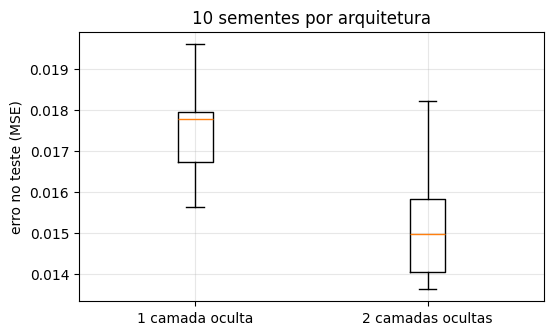

In [28]:
def criar_1camada():
    return nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 1))

def criar_2camadas():
    return nn.Sequential(nn.Linear(1, 10), nn.ReLU(), nn.Linear(10, 10), nn.ReLU(), nn.Linear(10, 1))

resultados = {"1 camada oculta": [], "2 camadas ocultas": []}
for semente in range(10):
    for nome, criar in [("1 camada oculta", criar_1camada), ("2 camadas ocultas", criar_2camadas)]:
        torch.manual_seed(semente)
        modelo = criar()
        treinar(modelo, X_treino, Y_treino, epocas=2000)
        resultados[nome].append(erro_teste(modelo))

for nome, erros in resultados.items():
    erros = np.array(erros)
    print(f"{nome:18s} | erro no teste: média = {erros.mean():.4f} | desvio = {erros.std():.4f} | "
          f"mín = {erros.min():.4f} | máx = {erros.max():.4f}")

plt.figure(figsize=(6, 3.5))
plt.boxplot(list(resultados.values()), tick_labels=list(resultados.keys()))
plt.ylabel("erro no teste (MSE)"); plt.title("10 sementes por arquitetura"); plt.grid(alpha=0.3)
plt.show()

**Quanto ainda dá para melhorar?** Como os dados são artificiais, posso calcular o erro da própria função verdadeira $\sin(1.5x) + 0.3x$. Ela não erra nada no "padrão"; o que sobra é só o ruído aleatório que foi somado aos dados. Esse é o **erro irredutível**: nenhum modelo consegue ficar consistentemente abaixo dele.

In [29]:
def funcao_verdadeira(x):
    return np.sin(1.5 * x) + 0.3 * x

ruido_treino = np.mean((y_treino - funcao_verdadeira(x_treino)) ** 2)
ruido_teste  = np.mean((y_teste  - funcao_verdadeira(x_teste))  ** 2)

print(f"erro da função verdadeira | treino = {ruido_treino:.4f} | teste = {ruido_teste:.4f}\n")
for nome, modelo, hist in [("ReLU, 1 camada", rede_relu, hist_relu),
                           ("Tanh, 1 camada", rede_tanh, hist_tanh),
                           ("ReLU, 2 camadas", rede_2camadas, hist_2camadas)]:
    print(f"{nome:16s} | treino = {hist[-1]:.4f} | teste = {erro_teste(modelo):.4f}")

erro da função verdadeira | treino = 0.0140 | teste = 0.0134

ReLU, 1 camada   | treino = 0.0147 | teste = 0.0171
Tanh, 1 camada   | treino = 0.0135 | teste = 0.0132
ReLU, 2 camadas  | treino = 0.0124 | teste = 0.0139


**Interpretação — Exercício 3**

- **A rede ficou bem maior.** Passou de 31 para 141 parâmetros, quase cinco vezes mais. Quase todo o aumento vem da matriz $10 \times 10$ que liga as duas camadas ocultas.
- **O ajuste melhorou um pouco.** A curva de duas camadas acompanha melhor o vale e o topo, e se achata nas pontas, perto de $x = \pm 3$, onde os dados também ficam mais planos. O erro no treino e no teste ficou menor que o da rede com uma camada.
- **A melhora se repete com outras sementes.** Nas 10 repetições, a rede de duas camadas teve erro médio no teste menor, e sua mediana ficou abaixo do melhor resultado da rede de uma camada. A melhora é **consistente, mas pequena**.
- **A curva de aprendizado caiu mais rápido.** A rede mais profunda chegou ao patamar final antes da rede rasa.
- **Já estamos no limite do que os dados permitem.** O erro da própria função verdadeira no teste é cerca de 0.013. A rede de duas camadas chega praticamente nesse valor, então não sobra quase nada para melhorar. No treino, ela até fica **abaixo** do erro da função verdadeira. Isso é um sinal de que ela começou a "decorar" um pouco do ruído dos pontos de treino, ou seja, um leve início de sobreajuste (*overfitting*).

**Conclusão:** uma segunda camada deu mais flexibilidade e uma melhora real, porém pequena. Para um problema simples como este, com uma entrada e poucos dados, uma camada oculta com 10 neurônios já resolve bem. Como na Seção 7, mais parâmetros só ajudam até certo ponto.

---
### Exercício 4 — Prevendo fora dos dados: $x = 10$

> Use a rede treinada para prever $y$ em $x = 10$, um valor bem fora dos dados de treino. O resultado faz sentido?

Os dados de treino vão apenas de $x=-3$ a $x=3$. Como os dados foram gerados artificialmente, sabemos a função verdadeira (sem ruído): $y = \sin(1.5x) + 0.3x$. Em $x = 10$ ela vale $\sin(15) + 3 \approx 3.65$. Comparo esse valor com a previsão de todos os modelos treinados.

In [30]:
x_novo = torch.tensor([[10.0]])
y_verdadeiro = np.sin(1.5 * 10) + 0.3 * 10

modelos = {
    "reta (Seção 3)": reta,
    "rede ReLU (Seção 4)": rede,
    "rede ReLU (referência)": rede_relu,
    "rede Tanh (Ex. 1)": rede_tanh,
    "2 camadas ocultas (Ex. 3)": rede_2camadas,
}

print(f"valor verdadeiro em x = 10: {y_verdadeiro:.3f}\n")
with torch.no_grad():
    for nome, modelo in modelos.items():
        y_prev = modelo(x_novo).item()
        print(f"{nome:27s} -> y previsto = {y_prev:7.3f}  (erro = {y_prev - y_verdadeiro:+.3f})")

valor verdadeiro em x = 10: 3.650

reta (Seção 3)              -> y previsto =   2.811  (erro = -0.839)
rede ReLU (Seção 4)         -> y previsto =  -6.508  (erro = -10.158)
rede ReLU (referência)      -> y previsto =  -6.551  (erro = -10.201)
rede Tanh (Ex. 1)           -> y previsto =  -0.458  (erro = -4.109)
2 camadas ocultas (Ex. 3)   -> y previsto =   0.354  (erro = -3.296)


Para entender **por que** cada modelo prevê o que prevê, desenho as curvas num intervalo bem maior que o dos dados, de $-12$ a $12$. A faixa cinza marca a região onde havia dados de treino.

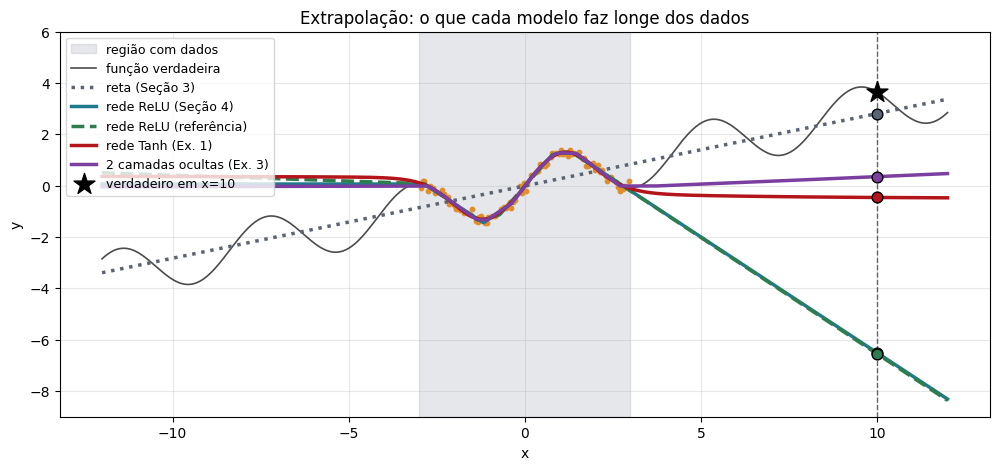

In [31]:
x_longe = torch.linspace(-12, 12, 600).reshape(-1, 1)
y_funcao = np.sin(1.5 * x_longe.numpy()) + 0.3 * x_longe.numpy()

plt.figure(figsize=(12, 5))
plt.axvspan(-3, 3, color=CINZA, alpha=0.15, label="região com dados")
plt.plot(x_longe, y_funcao, color="black", linewidth=1.2, alpha=0.7, label="função verdadeira")
plt.scatter(x_treino, y_treino, color=LARANJA, s=10)

cores = [CINZA, AZUL, VERDE, VERMELHO, "#7B3FA0"]
estilos = [":", "-", "--", "-", "-"]
with torch.no_grad():
    for (nome, modelo), cor, estilo in zip(modelos.items(), cores, estilos):
        plt.plot(x_longe, modelo(x_longe), color=cor, linewidth=2.5, linestyle=estilo, label=nome)
        plt.scatter([10], [modelo(x_novo).item()], color=cor, s=60, zorder=5, edgecolor="black")

plt.scatter([10], [y_verdadeiro], color="black", marker="*", s=250, zorder=6, label="verdadeiro em x=10")
plt.axvline(10, color=CINZA, linestyle="--", linewidth=1)
plt.ylim(-9, 6)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Extrapolação: o que cada modelo faz longe dos dados")
plt.legend(loc="upper left", fontsize=9); plt.grid(alpha=0.3)
plt.show()

Uma rede ReLU é uma função **linear por partes**. Depois da última "dobra", ela vira uma reta e continua assim até o infinito. Posso conferir isso calculando a inclinação da rede ReLU longe dos dados, em vários trechos à direita.

In [32]:
xs = torch.tensor([[4.0], [6.0], [10.0], [20.0], [100.0]])
with torch.no_grad():
    ys_relu = rede_relu(xs).squeeze()
    ys_tanh = rede_tanh(xs).squeeze()

print("inclinação da rede ReLU entre pontos consecutivos:")
for i in range(len(xs) - 1):
    a = (ys_relu[i + 1] - ys_relu[i]) / (xs[i + 1] - xs[i])
    print(f"  de x = {xs[i].item():5.0f} a x = {xs[i+1].item():5.0f}: {a.item():.4f}")

print("\nprevisões da rede Tanh, cada vez mais longe:")
for xv, yv in zip(xs, ys_tanh):
    print(f"  x = {xv.item():5.0f} -> y = {yv.item():.4f}")

inclinação da rede ReLU entre pontos consecutivos:
  de x =     4 a x =     6: -0.9069
  de x =     6 a x =    10: -0.9069
  de x =    10 a x =    20: -0.9069
  de x =    20 a x =   100: -0.9069

previsões da rede Tanh, cada vez mais longe:
  x =     4 -> y = -0.3273
  x =     6 -> y = -0.4036
  x =    10 -> y = -0.4584
  x =    20 -> y = -0.4863
  x =   100 -> y = -0.4898


**Interpretação — Exercício 4**

**Não, o resultado não faz sentido.** A rede ReLU prevê um valor em torno de $-6.5$ para $x = 10$, enquanto o valor verdadeiro é cerca de $3.65$. O erro é de mais de 10 unidades, e até o **sinal** está errado.

**Por que isso acontece?**

- **A rede só aprendeu o trecho entre $-3$ e $3$.** Fora desse intervalo, ela nunca viu nenhum exemplo. Nada no treino diz como a curva deveria se comportar ali.
- **A rede ReLU vira uma reta depois da última dobra.** Toda rede ReLU é linear por partes. Depois do último ponto de dobra, todos os neurônios ficam com o mesmo estado (ligado ou desligado), e a saída vira uma reta que segue para sempre. A tabela de inclinações confirma: entre $x = 4$ e $x = 100$ a inclinação é **sempre a mesma**, cerca de $-0.91$. É exatamente a inclinação do último trecho dos dados, perto de $x = 3$, onde a curva estava descendo. A rede apenas "continuou descendo".
- **Cada arquitetura extrapola de um jeito diferente.** A rede Tanh satura e fica praticamente constante, perto de $-0.49$, porque todos os neurônios ficam presos em $\pm 1$. A rede de duas camadas ficou quase plana. Nenhuma delas acerta.
- **A reta foi o modelo que chegou mais perto.** Isso parece estranho, porque ela era o pior modelo dentro dos dados. A explicação é que a função verdadeira tem uma tendência linear, o termo $0.3x$, e a reta captura justamente essa tendência. Mesmo assim, ela ignora completamente a oscilação do seno. O acerto vem mais da sorte de a tendência ser linear do que de um aprendizado real.

**Conclusão:** redes neurais são boas para **interpolar**, ou seja, prever dentro da região coberta pelos dados de treino. Elas não são confiáveis para **extrapolar**, ou seja, prever longe dessa região. O modelo não "sabe que não sabe": ele devolve um número com a mesma confiança dentro ou fora dos dados. Na prática, antes de usar um modelo é importante conferir se a nova entrada está dentro da faixa vista no treino.

---
### Conclusões gerais

1. **A função de ativação define a forma da curva.** A ReLU gera funções lineares por partes, com quinas. A Tanh gera funções suaves. Para este problema, cuja função verdadeira é suave, as duas funcionam bem.
2. **O número de épocas precisa ser suficiente.** Com poucas épocas, a rede ainda não terminou de aprender. A curva de aprendizado mostra quando a perda se estabiliza e não vale mais a pena continuar.
3. **Mais camadas trazem mais flexibilidade, mas com retorno decrescente.** A segunda camada ajudou um pouco, mas o erro já estava perto do limite imposto pelo ruído dos dados.
4. **Um modelo só é confiável dentro da região dos dados de treino.** Longe dela, cada arquitetura extrapola de um jeito arbitrário, e o resultado pode ser absurdo.